# ¿Cuándo aporta información el acoplamiento estructural?

**Pregunta:** ¿Qué demuestra el gradiente cruzado sobre dos campos acotados y qué permanece no identificable?

**Nivel 1 — hipótesis inversa**  
**Prerrequisitos:** gradientes, vectores e inversión de campos potenciales; 25 min.

## Objetivos

Tratar la estructura compartida como prior comprobable, calcular su diagnóstico por celda y examinar una ambigüedad central: una penalización nula no significa que las observaciones determinen alguna propiedad.

## Preparación

Instale las dependencias exactas del notebook:

```bash
pip install numpy==2.2.6 scipy==1.15.2 matplotlib==3.10.8 simpeg==0.25.2 discretize==0.12.0
```

La celda de preparación siguiente importa el método del repositorio y los paquetes fijados; no los instala.

## Datos

El control local diseñado contiene doce celdas activas y seis receptores gravimétricos más seis magnéticos en coordenadas ENU locales. Densidad y susceptibilidad son campos acotados prescritos; no hay observaciones de campo. Los receptores magnéticos están cinco metros al este, por lo que las modalidades no muestrean de forma idéntica. La hipótesis es que, donde varían ambas propiedades, sus gradientes podrían indicar contactos con orientación similar.

## Método

Para campos escalares ρ y χ, el gradiente cruzado es ∇ρ × ∇χ. Su magnitud se anula si un campo es localmente constante o si los gradientes son paralelos o antiparalelos. Un valor pequeño admite varias explicaciones: no distingue un contacto compartido de dos campos planos ni indica si alguna propiedad predice datos medidos. Este notebook aísla esa lógica antes de ponderar objetivos o comparar implementaciones.

In [1]:
# Importe el evaluador físico fijado y muestre las versiones del entorno.
from pathlib import Path
import sys
from importlib.metadata import version
import numpy as np
import matplotlib.pyplot as plt

root = next(
    p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data-pipeline/joint_survey_structure.py").is_file()
)
sys.path.insert(0, str(root / "data-pipeline"))
import joint_survey_plan as planner
import joint_survey_structure as physical_structure

print("NumPy", version("numpy"), "SimPEG", version("simpeg"), "discretize", version("discretize"))


NumPy 2.2.6 SimPEG 0.25.2 discretize 0.12.0


### Control físico: dos propiedades, dos sensibilidades

El control diseñado de doce celdas aporta geometría y vectores acotados de densidad y susceptibilidad. La gravedad responde a densidad mediante su operador de campos potenciales; el magnetismo responde a susceptibilidad bajo el campo inductor declarado. Difieren en unidades, huella espacial y coordenadas. Los vectores son entradas explicativas, no estimaciones. El regularizador ve su disposición, no los residuos de datos.


In [2]:
# Defina un control ENU pequeño de creación propia y sus escalas físicas declaradas.
receivers = np.array(
    [20, 30, 100, 50, 80, 110, -90, 40, 130, 10, -10, 150, 90, -50, 120, 130, 40, 160], dtype=float
).reshape(6, 3)
mag_receivers = receivers + [5, 0, 0]
src = dict(
    citation="Authored numerical control, not field data",
    raw_bytes=123,
    rights="private_use",
    correction_sha256="c" * 64,
)
g_source = dict(src, source_id="gravity", raw_sha256="a" * 64)
m_source = dict(src, source_id="magnetic", raw_sha256="b" * 64)
noise = dict(basis="measured_gaussian", cross_partition="declared_absent", citation="Authored error control")
noise_g = dict(noise, kind="diagonal_sd", unit="mGal")
noise_m = dict(noise, kind="diagonal_sd", unit="nT")
common = dict(reference_id="authored-local-enu", mask=np.zeros(6, bool), missing_reasons=("",) * 6)
common.update(groups=np.array([0, 0, 1, 1, 2, 2]), partition=np.array([0, 0, 1, 1, 2, 2]))
gravity = dict(common, source=g_source, component="gz_up", unit="mGal", receivers_m=receivers, noise=noise_g)
field = dict(amplitude_nt=50000.0, inclination_deg=60.0, declination_deg=12.0)


### Coordenadas de adquisición e incertidumbre

Seis estaciones ENU locales definen cada sondeo. Los receptores magnéticos están cinco metros al este de los gravimétricos correspondientes, por lo que no debe suponerse muestreo coincidente. Errores gaussianos independientes y grupos de adquisición documentan el contrato sintético; no se infieren de repeticiones. Deriva correlacionada, correcciones de terreno, remanencia y efectos instrumentales pueden invalidarlo. Deben incluirse en los modelos directos y covarianzas por modalidad.


In [3]:
# Conserve escalas y orden de malla declarados: ambos intervienen en la derivada discreta.
magnetic = dict(
    common,
    source=m_source,
    component="linear_tmi",
    unit="nT",
    receivers_m=mag_receivers,
    noise=noise_m,
    inducing_field=field,
)
density = dict(
    lower=np.full(12, -1500.0),
    upper=np.full(12, 1500.0),
    start=np.zeros(12),
    reference=np.zeros(12),
    scale=750.0,
)
susceptibility = dict(
    lower=np.zeros(12),
    upper=np.full(12, 0.1),
    start=np.full(12, 0.005),
    reference=np.full(12, 0.005),
    scale=0.03,
)


### Malla, soporte activo y límites

La malla registra origen, dimensiones de celda, máscara activa y eje vertical positivo. Densidad y susceptibilidad tienen escalas y límites distintos. Afectan derivadas y significado del prior normalizado; son supuestos, no valores recuperados. Celdas inactivas no aportan información. Una celda activa con baja sensibilidad puede seguir indeterminada aunque su gradiente cruzado sea cero.


In [4]:
# Conserve escalas y orden de malla declarados: ambos intervienen en la derivada discreta.
frame = dict(
    kind="local_cartesian",
    axes=("east", "north", "up"),
    length_unit="m",
    vertical_positive="up",
    reference_id="authored-local-enu",
)
frame.update(horizontal_datum="declared local origin", vertical_datum="declared elevation datum")
mesh = dict(
    origin_m=np.array([-140.0, -180.0, -260.0]),
    hx_m=np.array([40.0, 70.0, 90.0]),
    hy_m=np.array([30.0, 50.0]),
    hz_m=np.array([60.0, 110.0]),
    active=np.ones(12, bool),
)
prior = dict(
    density=density,
    susceptibility=susceptibility,
    lengths_m=np.array([60.0, 110.0, 75.0]),
    coupling_length_m=100.0,
    basis="Declared physical scales",
)


### Validar el plan no recupera propiedades

El planificador valida la solicitud y devuelve metadatos normalizados, semilla y orden x-fast. Hace repetibles los cálculos y detecta geometrías mal formadas, pero no resuelve propiedades. La identificabilidad exige comparar el prior con ambas sensibilidades de datos. La estructura compartida solo reduce modelos admisibles donde campos y observaciones aportan variación útil.


In [5]:
# Valide unidades, celdas activas y grupos antes de evaluar la cantidad estructural conjunta.
policy = dict(
    name="joint-survey-l2-cross-gradient-1", seed=42, cell_order="x-fast", training="not_applicable_classical"
)
policy.update(group_scope="global_acquisition", modal_covariance="independent")
physical_request = dict(
    schema="joint-survey-plan-request-1",
    frame=frame,
    mesh=mesh,
    gravity=gravity,
    magnetic=magnetic,
    prior=prior,
    policy=policy,
)
physical_plan = planner.plan_joint_survey(physical_request)
physical_n = 12
physical_rho, physical_chi = np.linspace(-400.0, 500.0, 12), np.linspace(0.004, 0.045, 12) + 0.002 * np.sin(
    np.arange(12)
)
physical_direction = np.sin(np.arange(24) + 0.3) / np.linalg.norm(np.sin(np.arange(24) + 0.3))
print("celdas activas creadas", int(physical_plan["mesh"]["active"].sum()), "número de receptores", len(receivers))


celdas activas creadas 12 número de receptores 6


### Paso 1 — evaluar la hipótesis estructural

Evalúe el gradiente cruzado normalizado para los campos prescritos. Es la intensidad de una penalización bajo esta malla activa y escala. No es desajuste gravimétrico o magnético ni probabilidad de contactos coincidentes. Para interpretarlo científicamente se requieren la parametrización y términos de datos independientes, ausentes aquí.


In [6]:
# Ejecute el método estructural real basado en SimPEG.
r = physical_structure.evaluate_joint_structure(
    {
        "schema": "joint-survey-structure-request-1",
        "survey_request": physical_request,
        "density_kg_m3": physical_rho,
        "susceptibility_si": physical_chi,
        "direction_physical": physical_direction,
    }
)
print("objetivo", r['objective'], "optimizer_completed", r["optimizer_completed"])


objetivo 0.012770248999752326 optimizer_completed False


### Paso 2 — inspeccionar derivada y soporte

El evaluador devuelve gradiente respecto de parámetros conjuntos y diagnóstico por celda. Una derivada no nula señala direcciones que cambian localmente el regularizador. Una derivada nula puede deberse a un campo plano, gradientes paralelos, bordes o escalamiento. No demuestra restricción por datos. Distinga sensibilidad del prior de los jacobianos directos gravimétrico y magnético.


In [7]:
# Inspeccione la derivada física devuelta y el diagnóstico de celdas activas.
g = np.asarray(r["gradient_physical"])
print(
    "forma del gradiente",
    g.shape,
    "norma",
    np.linalg.norm(g),
    "celdas de diagnóstico",
    len(r["cell_centre_cross_gradient"]),
)


forma del gradiente (24,) norma 5.744106660599303 celdas de diagnóstico 12


### Paso 3 — verificar una derivada direccional

La diferencia finita central perturba en ambos sentidos la dirección conjunta normalizada. La concordancia con la derivada analítica prueba consistencia numérica local para este modelo y paso. No prueba convexidad, convergencia ni identificabilidad. Esta última depende del jacobiano combinado, covarianza, límites y prior; aquí se mide solo un componente previo.


In [8]:
# Perturbe ambas propiedades a lo largo de una dirección física declarada.
h = 1e-3


def f(a, b):
    return physical_structure.evaluate_joint_structure(
        {
            "schema": "joint-survey-structure-request-1",
            "survey_request": physical_request,
            "density_kg_m3": a,
            "susceptibility_si": b,
            "direction_physical": physical_direction,
        }
    )['objective']


fd = (
    f(physical_rho + h * physical_direction[:physical_n], physical_chi + h * physical_direction[physical_n:])
    - f(physical_rho - h * physical_direction[:physical_n], physical_chi - h * physical_direction[physical_n:])
) / (2 * h)
print(
    "gradiente por dirección",
    float(g @ physical_direction),
    "diferencia finita",
    fd,
    "gap",
    abs(float(g @ physical_direction) - fd),
)


gradiente por dirección 3.5699340755498583 diferencia finita 3.569933992523068 gap 8.302679033178606e-08


### Diagnóstico estructural por celda

El arreglo contiene aportes del evaluador en cada celda activa para el par diseñado de densidad y susceptibilidad. Su orden sigue la malla, pero no es un mapa porque omite coordenadas. Los valores no nulos ubican gradientes prescritos discordantes tras escalar. No identifican su causa física ni prueban respaldo observacional de las propiedades.


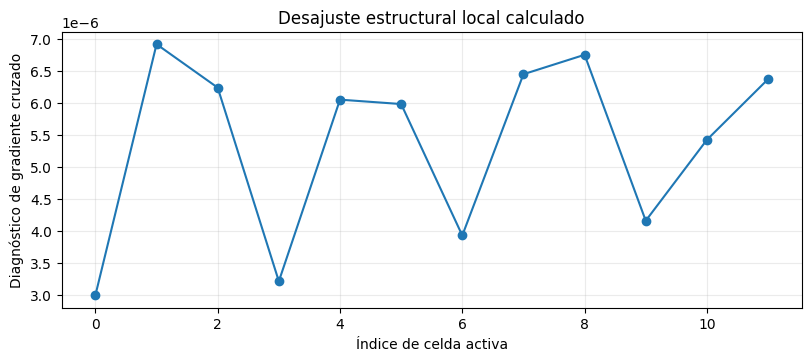

In [9]:
# Grafique el diagnóstico calculado por celda.
fig, ax = plt.subplots(figsize=(8, 3.5), constrained_layout=True)
d = np.asarray(r["cell_centre_cross_gradient"])
ax.plot(np.arange(len(d)), d, "o-")
ax.set(
    xlabel="Índice de celda activa", ylabel="Diagnóstico de gradiente cruzado", title="Desajuste estructural local calculado"
)
ax.grid(alpha=0.25)
plt.show()


### Interpretación de la figura

Cada marcador representa una celda activa en orden de malla. La figura muestra cómo una norma agregada puede ocultar el origen de la penalización y también el límite de esta vista: faltan coordenadas. Aportes nulos son compatibles con gradientes alineados y campos planos. Se evalúa el prior para un par diseñado; no se resuelve la hipótesis inversa ni se establece un límite geológico común.




## Resultados

**Respuesta:** El par diseñado de doce celdas da objetivo 0.01277025 y brecha de derivada direccional por diferencia finita 8.30e-08. Es un cálculo local; no se invirtieron observaciones.

## Resumen

El gradiente cruzado expresa una hipótesis de estructura compartida, pero sus valores no son diagnósticos únicos. Importan planitud, alineación, escala y discretización. Evalúe identificabilidad con sensibilidades por modalidad, ruido y geología independiente.

## Referencias

- Cockett et al. (2015), [SimPEG](https://doi.org/10.1016/j.cageo.2015.09.015)
- [Tutorial de gradiente cruzado de SimPEG](https://docs.simpeg.xyz/latest/content/user-guide/tutorials/13_joint_inversion/plot_inv_3_cross_gradient_pf.html)
- `data-pipeline/joint_survey_plan.py`; `data-pipeline/joint_survey_structure.py`
